# Tugas Besar 2 IF3170 Inteligensi Artifisial

## SVM Final dengan Preprocessing Kelompok

Satu eksperimen tambahan untuk menghasilkan satu CSV final dengan preprocessing dari template kelompok.

---

## Group 17 (DerbyCounty)

- Juan Oloando Simanungkalit (13524032) - juanoloando.s@gmail.com
- Nashiruddin Akram (13524090) - akrambaasir@gmail.com
- Reinsen Silitonga (13524093) - reinsilitonga12@gmail.com
- Arghawisesa Dwinanda Arham (13524100) - arghaku.argha@gmail.com
- Manuel Thimoty Silalahi (13524102) - manuelsilalahi06@gmail.com

## Table of Contents

1. [Introduction](#1)
2. [Initialization](#2)
3. [Data Understanding](#3)
4. [Training and Validation Split](#4)
5. [Data Preparation](#5)
6. [Preparation Pipeline](#6)
7. [Modeling and Validation](#7)
8. [Comparison with scikit-learn](#8)
9. [Saving and Loading Models](#9)
10. [Kaggle Submission](#10)
11. [Error Analysis](#11)
12. [Bonus](#12)
13. [Referensi](#13)

---

# Introduction <a name="1"></a>

---

## Overview

Penginapan ingin memprediksi pembatalan pemesanan dari informasi tamu, tanggal kedatangan,
kanal pemesanan, harga, dan permintaan khusus. Target `is_canceled` bernilai 1 untuk pemesanan batal.

## Aim

Mengevaluasi SVM from scratch dan membandingkannya dengan scikit-learn pada pembagian data
dan preprocessing yang sama. Bagian model lain dibiarkan kosong karena notebook ini khusus SVM.

## Metric

Macro F1 merupakan rata-rata F1 kelas batal dan tidak batal. Threshold dipilih dari prediksi
out-of-fold pada data train. Nilai OOF yang juga dipakai memilih threshold bukan estimasi independen.

## Dataset

Input berada pada `data/train.csv`, `data/test.csv`, dan `data/sample_submission.csv`.
Train dan test diproses terpisah. Test tidak digunakan untuk memilih parameter atau threshold.

## Approach

Preprocessing mengikuti fungsi `prepare` pada template kelompok dan diimplementasikan sebagai
`FinalSVMPreprocessor` langsung pada notebook ini. Statistik hasil fit disimpan bersama model.
Urutannya adalah penandaan data tidak valid, clipping, fitur turunan, imputasi, robust scaling,
bobot fitur, dan one-hot. Statistik hanya dipelajari dari data fit.

Konfigurasi Linear, Polynomial, dan Gaussian disaring dengan pembanding scikit-learn pada sampel stratified dari train menggunakan Macro F1 OOF. Skor screening bukan skor from scratch.
Kandidat terbaik tiap kernel diprioritaskan dari screening dan diperiksa pada lima fold seluruh train sampai target OOF lama terlampaui. Pemenang yang sudah diverifikasi dilatih menjadi
satu model final. Seluruh pemilihan memakai train, tanpa label test atau skor public Kaggle.
Public Kaggle terverifikasi adalah **0,85189**, submission **58803590**. Hanya satu CSV final dihasilkan oleh notebook ini.

---

# Initialization <a name="2"></a>

---

## Environment Setup

Jalankan `pip install -r requirements.txt jupyter` dari root repo.
Seluruh grafik menggunakan Matplotlib dan disimpan sebagai PNG.
Perangkat CPU dipakai secara default agar tidak memerlukan PyTorch.

## Import Libraries

In [1]:
import pickle
from scipy.optimize import minimize
from matplotlib.lines import Line2D
import hashlib
import inspect
import json
import random
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython import get_ipython
from IPython.display import Code, Markdown, display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/train.csv').is_file())

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Python', sys.version.split()[0], '| NumPy', np.__version__,
      '| pandas', pd.__version__, '| SciPy', scipy.__version__, '| sklearn', sklearn.__version__)

Python 3.12.6 | NumPy 2.2.6 | pandas 2.3.0 | SciPy 1.16.2 | sklearn 1.9.0


### Utilitas Data dan Validasi

Cleaning, metrik, dan validasi silang didefinisikan di notebook ini.

In [ ]:
TARGET = 'is_canceled'

ID_COL = 'id'

CAT_COLS = ['meal_package', 'room_category', 'booking_channel']

def clean_train(df):
    feature_cols = [c for c in df.columns if c != ID_COL]
    return df.drop_duplicates(subset=feature_cols).reset_index(drop=True)

def mark_invalid(df):
    df = df.copy()
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
    return df

def add_features(df):
    df = df.copy()
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['is_free'] = (df['nightly_rate_idr'] == 0).astype(float)
    df.loc[df['nightly_rate_idr'].isna(), 'is_free'] = np.nan
    df['rate_per_guest'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)

    arrival = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']),
        errors='coerce',
    )
    df['arrival_weekday'] = arrival.dt.weekday.astype(float)
    df['arrival_dayofyear'] = arrival.dt.dayofyear.astype(float)
    df['arrival_index'] = ((arrival - pd.Timestamp('2023-01-01')).dt.days).astype(float)
    return df

def save_model(bundle, path):
    # Simpan state agar pickle tidak bergantung pada modul model di luar notebook.
    bundle = dict(bundle)
    for key in ['model', 'preprocessor']:
        obj = bundle.get(key)
        if obj is not None:
            bundle[key + '_state'] = vars(obj).copy()
            bundle[key + '_class'] = type(obj).__name__
            del bundle[key]
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('wb') as file:
        pickle.dump(bundle, file)


def load_model(path):
    with Path(path).open('rb') as file:
        bundle = pickle.load(file)
    for key, default in [('model', 'SVM'), ('preprocessor', 'SVMPreprocessor')]:
        if key + '_state' in bundle:
            cls = globals().get(bundle.get(key + '_class', default))
            if cls is None:
                raise RuntimeError('Jalankan sel definisi kelas sebelum load model.')
            obj = cls.__new__(cls)
            obj.__dict__.update(bundle[key + '_state'])
            bundle[key] = obj
    return bundle


def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])

def f1_per_class(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    f1_pos = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn > 0 else 0.0
    f1_neg = 2 * tn / (2 * tn + fn + fp) if tn + fn + fp > 0 else 0.0
    return np.array([f1_neg, f1_pos])

def macro_f1(y_true, y_pred):
    return float(f1_per_class(y_true, y_pred).mean())

def accuracy(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

def best_threshold(y_true, proba, grid=None):
    if grid is None:
        grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    scores = np.array([macro_f1(y_true, (proba >= t).astype(int)) for t in grid])
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])

def stratified_kfold(y, n_splits=5, seed=42):
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]

def cross_val_proba(make_model, make_prep, df, y, folds):
    y = np.asarray(y)
    oof = np.zeros(len(y))
    for tr_idx, va_idx in folds:
        prep = make_prep()
        X_tr = prep.fit_transform(df.iloc[tr_idx])
        X_va = prep.transform(df.iloc[va_idx])
        model = make_model()
        model.fit(X_tr, y[tr_idx])
        oof[va_idx] = model.predict_proba(X_va)
    return oof

def fold_scores(y, proba, folds, threshold):
    y = np.asarray(y)
    pred = (proba >= threshold).astype(int)
    return np.array([macro_f1(y[va], pred[va]) for _, va in folds])

## Settings

In [2]:
EXP_NAME = 'svm_final'
PARAMS = {'kernel': 'linear', 'C': 0.1}
SEED = 5
N_FOLDS = 5
TEST_SIZE = 0.2
# CUDA hanya mempercepat kernel, solver SLSQP tetap berjalan pada CPU.
DEVICE = 'cpu'
SMOKE_TEST = False
SCREEN_ROWS = 1200
TARGET_OOF = 0.7943359038789102 + 0.003
COMMON_PARAMS = dict(tol=0.01, max_iter=1000, seed=SEED, device=DEVICE)
KAGGLE_PUBLIC_SCORE = 0.85189
KAGGLE_SUBMISSION_ID = 58803590

DATA_DIR = ROOT / 'data'
RUN_DIR = ROOT / 'output/experiments' / EXP_NAME / ('smoke' if SMOKE_TEST else 'template_rerun')
FIG_DIR = (RUN_DIR / 'figures') if SMOKE_TEST else ROOT / 'output/figures' / EXP_NAME
MODEL_PATH = (RUN_DIR if SMOKE_TEST else ROOT / 'output/models') / (EXP_NAME + '.pkl')
RERUN_SUB_PATH = (RUN_DIR if SMOKE_TEST else ROOT / 'output/submissions') / ('submission_' + EXP_NAME + '.csv')
DEV_SIZE, HOLDOUT_SIZE, VISUAL_SIZE = (160, 80, 100) if SMOKE_TEST else (800, 400, 400)
PARTICLES, GENERATIONS = (3, 2) if SMOKE_TEST else (8, 4)
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Mode:', 'uji kecil' if SMOKE_TEST else 'seluruh train', '| output:', RUN_DIR)

Mode: seluruh train | output: C:\Users\Akram\Documents\Semester5\AI\IF3170_G17_DerbyCounty\output\experiments\svm_final\template_rerun


`SMOKE_TEST=True` menjalankan pemeriksaan pada 320 baris train dan 12 baris test.
Mode penuh memakai seed 5 dan StratifiedKFold dari template kelompok.
Screening memakai maksimal 1.200 baris train. Linear menguji C sebesar 0,01, 0,1, dan 1. Polynomial menguji C sebesar 0,1, 1, dan 10
pada derajat 2 dan 3. Gaussian menguji C sebesar 0,1, 0,3, 1, 3, dan 10
dengan gamma 0,01, 0,1, dan 1.
Semua kandidat memakai pembagian fold dan preprocessing yang sama.

## Seed Everything

In [3]:
random.seed(SEED)
np.random.seed(SEED)

## Load Dataset

In [4]:
train_raw = pd.read_csv(DATA_DIR / 'train.csv', dtype={'id': str})
test_raw = pd.read_csv(DATA_DIR / 'test.csv', dtype={'id': str})
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype={'id': str})
assert train_raw['id'].notna().all() and train_raw['id'].is_unique
assert test_raw['id'].notna().all() and test_raw['id'].is_unique
assert list(sample.columns) == ['id', TARGET] and test_raw['id'].equals(sample['id'])
assert set(train_raw[TARGET].unique()) == {0, 1}
print('Train:', train_raw.shape, '| test:', test_raw.shape)

Train: (27373, 19) | test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

## Describe Data

In [5]:
display(pd.DataFrame({'dtype': train_raw.dtypes.astype(str),
                      'missing': train_raw.isna().sum(), 'unique': train_raw.nunique()}))
display(train_raw.describe().round(2))

,dtype,missing,unique
id,object,0,27373
num_adults,float64,809,5
num_children,float64,3035,6
weekend_nights,int64,0,8
weekday_nights,int64,0,18
meal_package,object,1760,4
needs_parking,float64,1082,2
room_category,object,1002,7
days_before_arrival,float64,1123,407
arrival_year,int64,0,2


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.00,24338.00,27373.00,27373.00,26291.00,26250.00,27373.00,27373.00,27373.00,27373.00,27373.00,27373.00,25335.00,24873.00,27373.00
mean,1.85,0.12,0.81,2.21,0.03,85.38,2023.82,7.40,15.54,0.03,0.02,0.14,1716979.55,0.67,0.33
std,0.52,0.43,0.88,1.42,0.17,85.97,0.38,3.07,8.77,0.16,0.36,1.69,587936.77,0.80,0.47
min,0.00,0.00,0.00,0.00,0.00,0.00,2023.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,0.00,0.00,1.00,0.00,17.00,2024.00,5.00,8.00,0.00,0.00,0.00,1338000.00,0.00,0.00
50%,2.00,0.00,1.00,2.00,0.00,58.00,2024.00,8.00,16.00,0.00,0.00,0.00,1644000.00,0.00,0.00
75%,2.00,0.00,2.00,3.00,0.00,126.00,2024.00,10.00,23.00,0.00,0.00,0.00,2019000.00,1.00,1.00
max,4.00,10.00,7.00,17.00,1.00,448.00,2024.00,12.00,31.00,1.00,13.00,58.00,9165000.00,5.00,1.00


## Explore Data

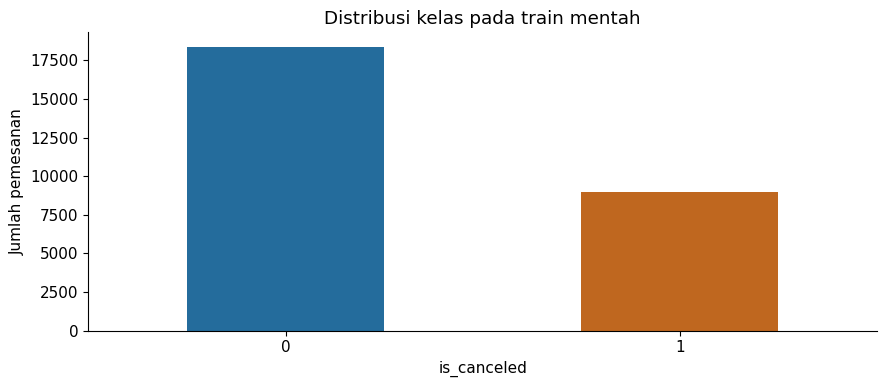

,proporsi
is_canceled,
0,0.6723
1,0.3277


In [6]:
counts = train_raw[TARGET].value_counts().sort_index()
ax = counts.plot.bar(color=['#246c9c', '#bf671f'], rot=0)
ax.set(title='Distribusi kelas pada train mentah', xlabel='is_canceled', ylabel='Jumlah pemesanan')
plt.tight_layout()
plt.savefig(FIG_DIR / 'class_balance.png', dpi=130)
plt.show()
display((counts / counts.sum()).rename('proporsi').to_frame().round(4))

#### Insights

Macro F1 memberi bobot yang sama kepada kedua kelas meskipun jumlah sampelnya berbeda.
Threshold OOF dan pembagian stratified digunakan untuk evaluasi. Resampling tidak diterapkan
pada eksperimen lama ini agar distribusi dan konfigurasi training tetap sesuai riwayatnya.

## Verify Data Quality

In [7]:
duplicate_cols = [c for c in train_raw if c != 'id']
display(pd.Series({'duplikat fitur dan target': train_raw.duplicated(duplicate_cols).sum(),
                   'num_adults nol': train_raw['num_adults'].eq(0).sum(),
                   'baris dengan missing': train_raw.isna().any(axis=1).sum()}))

duplikat fitur dan target       64
num_adults nol                 106
baris dengan missing         10737
dtype: int64

---

# Training and Validation Split <a name="4"></a>

---

Duplikat dengan fitur dan target identik dihapus sebelum pembagian data agar salinan baris
yang sama tidak tersebar ke train dan validasi. Holdout dipakai untuk pemeriksaan awal.
Evaluasi utama menggunakan lima fold pada train bersih dan tidak memakai label test.

In [8]:
train_clean = clean_train(train_raw)
if SMOKE_TEST:
    selected, _ = train_test_split(np.arange(len(train_clean)), train_size=320,
                                  stratify=train_clean[TARGET], random_state=SEED)
    train_clean = train_clean.iloc[selected].reset_index(drop=True)
    test_raw = test_raw.head(12).copy()
    sample = sample.head(12).copy()
y = train_clean[TARGET].to_numpy()
train_set, val_set = train_test_split(train_clean, test_size=TEST_SIZE,
                                     stratify=y, random_state=SEED)
y_train, y_val = train_set[TARGET].to_numpy(), val_set[TARGET].to_numpy()
folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(train_clean, y))
assert np.array_equal(np.sort(np.concatenate([va for _, va in folds])), np.arange(len(y)))
assert all(not np.intersect1d(tr, va).size for tr, va in folds)
print('Train bersih:', len(train_clean), '| train holdout:', len(train_set), '| validasi:', len(val_set))

Train bersih: 27309 | train holdout: 21847 | validasi: 5462


---

# Data Preparation <a name="5"></a>

---

In [ ]:
class FinalSVMPreprocessor:
    num_cols = ['num_adults', 'weekend_nights', 'weekday_nights', 'needs_parking',
                'days_before_arrival', 'arrival_day', 'is_returning_guest',
                'prior_cancellations', 'nightly_rate_idr', 'special_requests',
                'booking_index', 'month_cos']
    cat_cols = ['meal_package', 'room_category', 'booking_channel']
    clip_cols = ['num_adults', 'weekend_nights', 'weekday_nights', 'days_before_arrival',
                 'nightly_rate_idr', 'prior_cancellations', 'special_requests']

    def __init__(self, clip_quantile=0.005, onehot_value=0.75, feature_weights=None):
        self.clip_quantile = clip_quantile
        self.onehot_value = onehot_value
        self.feature_weights = dict(feature_weights if feature_weights is not None else {
            'days_before_arrival': 2.0, 'special_requests': 2.0, 'needs_parking': 0.5,
            'weekday_nights': 0.5, 'num_adults': 0.25,
        })

    @staticmethod
    def _invalid(df):
        df = df.copy()
        df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
        return df

    def _construct(self, df):
        df = df.copy()
        df[self.clip_cols] = df[self.clip_cols].clip(self.lower_, self.upper_, axis=1)
        arrival = pd.to_datetime(dict(year=df['arrival_year'], month=df['arrival_month'],
                                     day=df['arrival_day']), errors='coerce')
        df['booking_index'] = (arrival - pd.Timestamp('2023-01-01')).dt.days.astype(float) - df['days_before_arrival']
        df['month_cos'] = np.cos(2 * np.pi * df['arrival_month'] / 12)
        return df

    def fit(self, df):
        df = self._invalid(df)
        lower = df[self.clip_cols].quantile(self.clip_quantile)
        upper = df[self.clip_cols].quantile(1 - self.clip_quantile)
        same = lower >= upper
        self.lower_ = lower.where(~same, -np.inf)
        self.upper_ = upper.where(~same, np.inf)
        df = self._construct(df)
        # Fallback hanya berlaku jika seluruh kolom pada data fit kosong.
        self.medians_ = df[self.num_cols].median().fillna(0.0)
        self.modes_ = {c: df[c].mode().get(0, 'Other') for c in self.cat_cols}
        numeric = df[self.num_cols].fillna(self.medians_).astype(float)
        self.center_ = numeric.median()
        spread = numeric.quantile(0.75) - numeric.quantile(0.25)
        self.spread_ = spread.where(spread > 0, numeric.std()).replace(0, 1).fillna(1.0)
        self.levels_ = {c: sorted(df[c].fillna(self.modes_[c]).unique()) for c in self.cat_cols}
        self.columns_ = self.num_cols + [f'{c}_{level}' for c in self.cat_cols for level in self.levels_[c]]
        return self

    def transform(self, df):
        if not hasattr(self, 'columns_'):
            raise RuntimeError('Preprocessor harus di-fit sebelum transform.')
        df = self._construct(self._invalid(df))
        out = (df[self.num_cols].fillna(self.medians_).astype(float) - self.center_) / self.spread_
        for column, value in self.feature_weights.items():
            out[column] = out[column] * value
        # Level kategori mengikuti train, kategori baru menghasilkan semua kolom one-hot nol.
        for column in self.cat_cols:
            values = df[column].fillna(self.modes_[column])
            for level in self.levels_[column]:
                out[f'{column}_{level}'] = (values == level) * self.onehot_value
        return out[self.columns_].astype(np.float32)

    def fit_transform(self, df):
        return self.fit(df).transform(df)


Seluruh transformasi berikut merupakan bagian dari `FinalSVMPreprocessor`.
Contoh pada bagian ini hanya memperlihatkan hasil proses. Pipeline training di bagian berikutnya
membuat preprocessor baru dan mempelajari statistik hanya dari data fit.

## Select Data

Fitur numerik terpilih adalah `num_adults`, `weekend_nights`, `weekday_nights`, `needs_parking`,
`days_before_arrival`, `arrival_day`, `is_returning_guest`, `prior_cancellations`,
`nightly_rate_idr`, `special_requests`, `booking_index`, dan `month_cos`.
Tiga fitur kategori adalah `meal_package`, `room_category`, dan `booking_channel`.
ID dan target tidak ikut menjadi fitur.

In [9]:
display(pd.Index(FinalSVMPreprocessor.num_cols + FinalSVMPreprocessor.cat_cols, name='fitur terpilih'))

Index(['num_adults', 'weekend_nights', 'weekday_nights', 'needs_parking',
       'days_before_arrival', 'arrival_day', 'is_returning_guest',
       'prior_cancellations', 'nightly_rate_idr', 'special_requests',
       'booking_index', 'month_cos', 'meal_package', 'room_category',
       'booking_channel'],
      dtype='object', name='fitur terpilih')

## Clean Data

### Missing Values

Numerik diisi median dan kategorikal diisi modus data fit. Tidak ada indikator missing tambahan.
Fallback untuk kolom numerik yang seluruhnya kosong adalah 0 dan kategori kosong memakai `Other`.

### Duplicates

Duplikat fitur dan target pada train dihapus sebelum split sesuai template. Test tetap utuh.

### Outliers

Kolom yang dipilih template di-clip ke persentil 0,5 dan 99,5 dari data fit.
Kolom dengan kedua batas sama tidak di-clip.

### Data Errors

Nilai `num_adults=0` diubah menjadi missing sebelum clipping dan imputasi.

In [10]:
invalid_demo = mark_invalid(train_set)
display(pd.DataFrame({'missing sebelum': train_set.isna().sum(),
                      'missing setelah penandaan': invalid_demo.isna().sum()}))

,missing sebelum,missing setelah penandaan
id,0,0
num_adults,657,749
num_children,2450,2450
weekend_nights,0,0
weekday_nights,0,0
meal_package,1409,1409
needs_parking,851,851
room_category,812,812
days_before_arrival,895,895
arrival_year,0,0


## Construct Data

### Attribute Construction

`booking_index` merupakan indeks tanggal kedatangan dikurangi lead time.
`month_cos` adalah cosinus bulan kedatangan untuk merepresentasikan pola musiman.
Keduanya dihitung per baris sesuai template kelompok.

In [11]:
arrival_demo = pd.to_datetime(dict(year=train_set['arrival_year'], month=train_set['arrival_month'],
                                        day=train_set['arrival_day']), errors='coerce')
display(pd.DataFrame({'booking_index': (arrival_demo - pd.Timestamp('2023-01-01')).dt.days - train_set['days_before_arrival'],
                      'month_cos': np.cos(2 * np.pi * train_set['arrival_month'] / 12)}).head())

,booking_index,month_cos
23158,647.0,8.660254e-01
6939,532.0,-1.000000e+00
22591,406.0,5.000000e-01
16914,322.0,6.123234e-17
16072,356.0,-1.836970e-16


### Feature Scaling

Numerik diubah dengan `(x - median) / IQR`. Jika IQR nol, dipakai standar deviasi.
Sebaran nol atau tidak tersedia diganti 1. Median dan sebaran berasal dari data fit.
Bobot template adalah lead time dan permintaan khusus 2, parkir dan weekday nights 0,5,
serta jumlah dewasa 0,25.

### Encoding

Kategori diubah menjadi one-hot bernilai 0,75. Level mengikuti data fit.
Kategori baru pada validasi atau test menghasilkan nol pada seluruh kolom kategori terkait.

### Dimensionality Reduction

PCA tidak digunakan. Pemilihan fitur dan dua fitur tanggal mengikuti template.

## Class Balance

Proporsi kelas dijaga melalui StratifiedKFold. Macro F1 dan threshold OOF dipakai tanpa resampling.

## Format Data

Hasil berupa matriks float32 finite dengan urutan kolom yang sama pada fit dan transform.

---

# Preparation Pipeline <a name="6"></a>

---

In [12]:
prep_holdout = FinalSVMPreprocessor()
X_train = prep_holdout.fit_transform(train_set)
X_val = prep_holdout.transform(val_set)
X_test_demo = prep_holdout.transform(test_raw)
assert X_train.columns.equals(X_val.columns) and X_train.columns.equals(X_test_demo.columns)
assert 'id' not in X_train and TARGET not in X_train
assert all(np.isfinite(frame.to_numpy()).all() for frame in [X_train, X_val, X_test_demo])
display(pd.Series({'fitur hasil preprocessing': X_train.shape[1],
                   'train holdout': len(X_train), 'validasi': len(X_val), 'test': len(X_test_demo)}))

fitur hasil preprocessing       28
train holdout                21847
validasi                      5462
test                          6844
dtype: int64

---

# Modeling and Validation <a name="7"></a>

---

## K-Nearest Neighbors

## Decision Tree Learning

## Logistic Regression

## Support Vector Machine

SVM meminimalkan masalah dual dengan batas `0 <= alpha <= C` dan `sum(alpha * y) = 0`.
Linear memakai dot product, Polynomial memakai `(gamma * x.T @ z + coef0) ** degree`,
dan Gaussian memakai `exp(-gamma * ||x-z||²)`.

Optimasi blok SLSQP membatasi matriks kerja hingga 64 alpha. Kalibrasi sigmoid dengan BFGS
memetakan fungsi keputusan menjadi probabilitas menggunakan holdout internal dari data train.
Model utama tetap dilatih pada seluruh train fold.

In [ ]:
class SVM:

    # C mengatur penalti margin, tol toleransi optimasi, dan max_iter batas putaran training.
    def __init__(self, C=1.0, tol=1e-3, max_iter=1000, seed=42,
                 kernel='linear', degree=3, gamma='scale', coef0=0.0, device='cpu'):
        self.C = C
        self.tol = tol
        self.max_iter = max_iter
        self.seed = seed
        self.kernel = kernel
        self.degree = degree
        self.gamma = gamma
        self.coef0 = coef0
        self.device = device

    # Latih SVM, lalu pelajari kalibrasi probabilitas dari holdout di dalam data train.
    def fit(self, X, y):
        X = self._validate_X(X)
        y = np.asarray(y)
        if y.ndim != 1 or len(y) != len(X) or not np.isfinite(y).all():
            raise ValueError('y harus berupa vektor label numerik finite sepanjang X.')
        classes = np.unique(y)
        if len(classes) != 2:
            raise ValueError('SVM membutuhkan tepat dua kelas pada data train.')
        if not np.isfinite(self.C) or self.C <= 0:
            raise ValueError('C harus positif dan finite.')
        if not np.isfinite(self.tol) or self.tol <= 0:
            raise ValueError('tol harus positif dan finite.')
        if not isinstance(self.max_iter, (int, np.integer)) or self.max_iter < 1:
            raise ValueError('max_iter harus berupa bilangan bulat positif.')
        # Alias lama dipertahankan agar pemanggil dan model tersimpan tetap dapat digunakan.
        if self.kernel not in ('linear', 'poly', 'gaussian', 'rbf'):
            raise ValueError("kernel harus 'linear', 'poly', atau 'gaussian'.")
        if not isinstance(self.degree, (int, np.integer)) or self.degree < 1:
            raise ValueError('degree harus berupa bilangan bulat positif.')
        if not np.isfinite(self.coef0) or self.coef0 < 0:
            raise ValueError('coef0 harus nonnegatif dan finite.')
        if isinstance(self.gamma, str):
            if self.gamma not in ('scale', 'auto'):
                raise ValueError("gamma harus 'scale', 'auto', atau angka positif.")
        elif not np.isfinite(self.gamma) or self.gamma <= 0:
            raise ValueError('gamma harus positif dan finite.')

        self._fit_svm(X, y)
        self._calibrate(X, y)
        return self

    # Pecah QP dual menjadi blok kecil agar tidak menyimpan matriks kernel n x n.
    def _fit_svm(self, X, y):
        self.device_ = self._resolve_device()
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.n_features_in_ = X.shape[1]
        if self.gamma == 'scale':
            variance = X.var()
            self.gamma_ = 1.0 / (X.shape[1] * variance) if variance > 0 else 1.0
        elif self.gamma == 'auto':
            self.gamma_ = 1.0 / X.shape[1]
        else:
            self.gamma_ = float(self.gamma)

        signed_y = 2.0 * encoded - 1.0
        self.alpha_ = np.zeros(len(X))
        gradient = -np.ones(len(X))
        eps = 1e-8 * min(1.0, self.C)
        features = None
        if self.device_ == 'cuda':
            try:
                features = self._gpu_features(X)
            except MemoryError:
                if self.device != 'auto':
                    raise
                warnings.warn('Memori GPU tidak cukup; training beralih ke CPU.', RuntimeWarning)
                self.device_ = 'cpu'

        steps_per_pass = (len(X) + 63) // 64
        self.n_iter_ = 0
        for iteration in range(self.max_iter * steps_per_pass):
            # Dua himpunan kandidat memberi batas bawah dan atas bias pada kondisi KKT.
            values = -signed_y * gradient
            up = np.flatnonzero(((signed_y > 0) & (self.alpha_ < self.C - eps))
                                | ((signed_y < 0) & (self.alpha_ > eps)))
            low = np.flatnonzero(((signed_y > 0) & (self.alpha_ > eps))
                                 | ((signed_y < 0) & (self.alpha_ < self.C - eps)))
            if values[up].max() - values[low].min() <= 2.0 * self.tol:
                break
            working = np.unique(np.concatenate((up[np.argsort(values[up])[-32:]],
                                                low[np.argsort(values[low])[:32]])))
            if features is None:
                kernel = self._kernel(X, X[working])
            else:
                import torch
                try:
                    with torch.inference_mode():
                        kernel = self._kernel(features, features[working], xp=torch).cpu().numpy()
                except torch.cuda.OutOfMemoryError as error:
                    if self.device != 'auto':
                        raise MemoryError('VRAM tidak cukup untuk blok kernel SVM.') from error
                    warnings.warn('Memori GPU tidak cukup; training beralih ke CPU.', RuntimeWarning)
                    features = None
                    self.device_ = 'cpu'
                    kernel = self._kernel(X, X[working])
            columns = signed_y[:, None] * kernel * signed_y[working]
            block = columns[working]
            old = self.alpha_[working].copy()
            labels = signed_y[working]
            linear = gradient[working] - block @ old

            # SciPy menangani optimasi QP beserta batas alpha dan kendala jumlah alpha*y = 0.
            result = minimize(lambda a: (0.5 * a @ block @ a + linear @ a, block @ a + linear),
                              old, jac=True, method='SLSQP', bounds=[(0.0, self.C)] * len(old),
                              constraints={'type': 'eq', 'fun': lambda a: labels @ (a - old),
                                           'jac': lambda a: labels},
                              options={'ftol': min(1e-9, self.tol ** 2 * 1e-3), 'maxiter': 1000})
            if not result.success:
                raise RuntimeError(f'Solver QP SVM gagal: {result.message}')
            self.alpha_[working] = result.x
            gradient += columns @ (result.x - old)
            self.n_iter_ = iteration // steps_per_pass + 1

        values = -signed_y * gradient
        up = ((signed_y > 0) & (self.alpha_ < self.C - eps)) | ((signed_y < 0) & (self.alpha_ > eps))
        low = ((signed_y > 0) & (self.alpha_ > eps)) | ((signed_y < 0) & (self.alpha_ < self.C - eps))
        self.intercept_ = float((values[up].max() + values[low].min()) / 2.0)
        self.support_ = np.flatnonzero(self.alpha_ > eps)
        self.support_vectors_ = X[self.support_].copy()
        self.dual_coef_ = self.alpha_[self.support_] * signed_y[self.support_]
        self.coef_ = self.dual_coef_ @ self.support_vectors_ if self.kernel == 'linear' else None
        residual = signed_y * self.decision_function(X) - 1.0
        self.converged_ = not (((residual < -self.tol) & (self.alpha_ < self.C - eps))
                              | ((residual > self.tol) & (self.alpha_ > eps))).any()
        if not self.converged_:
            warnings.warn('SVM berhenti sebelum seluruh kondisi KKT memenuhi tol. '
                          'Periksa scaling atau naikkan max_iter.', RuntimeWarning, stacklevel=2)
        return self

    @staticmethod
    def _gpu_features(X, torch_device='cuda'):
        import torch
        try:
            return torch.as_tensor(X, dtype=torch.float64, device=torch_device)
        except torch.cuda.OutOfMemoryError as error:
            raise MemoryError('VRAM tidak cukup untuk data SVM.') from error

    # PyTorch opsional: mode CPU dan prediksi model tersimpan tidak mengimpornya.
    def _resolve_device(self):
        device = getattr(self, 'device', 'cpu')
        if device not in ('cpu', 'cuda', 'auto'):
            raise ValueError("device harus 'cpu', 'cuda', atau 'auto'.")
        if device == 'cpu':
            return 'cpu'
        try:
            import torch
        except ImportError as error:
            if device == 'auto':
                return 'cpu'
            raise RuntimeError('device=cuda memerlukan PyTorch dengan dukungan CUDA.') from error
        if torch.cuda.is_available():
            return 'cuda'
        if device == 'auto':
            return 'cpu'
        raise RuntimeError('CUDA tidak tersedia. Aktifkan GPU dan gunakan PyTorch CUDA, atau device=cpu.')

    # Hitung kemiripan seluruh pasangan baris pada X dan Y.
    def _kernel(self, X, Y, xp=np):
        with np.errstate(over='ignore', invalid='ignore'):
            product = X @ Y.T
            if self.kernel == 'poly':
                result = (self.gamma_ * product + self.coef0) ** self.degree
            elif self.kernel in ('gaussian', 'rbf'):
                distance = (X ** 2).sum(axis=1)[:, None] + (Y ** 2).sum(axis=1) - 2.0 * product
                result = xp.exp(-self.gamma_ * distance.clip(0.0, None))
            else:
                result = product
        if not xp.isfinite(result).all():
            raise ValueError('Perhitungan kernel tidak finite, periksa scaling dan parameter kernel.')
        return result

    # Gunakan 20 persen dari tiap kelas untuk kalibrasi model sementara.
    def _calibrate(self, X, y):
        positive = y == self.classes_[1]
        counts = np.bincount(positive.astype(int), minlength=2)
        if counts.min() < 2:
            self.probA_ = 0.0
            self.probB_ = float(np.log((counts[0] + 1.0) / (counts[1] + 1.0)))
            warnings.warn('Sampel tiap kelas terlalu sedikit untuk holdout kalibrasi. '
                          'Probabilitas memakai prior kelas.', RuntimeWarning, stacklevel=2)
            return

        rng = np.random.default_rng(self.seed)
        holdout = []
        for label in self.classes_:
            indices = rng.permutation(np.flatnonzero(y == label))
            size = max(1, len(indices) // 5)
            holdout.extend(indices[:size])
        holdout = np.asarray(holdout)
        training = np.ones(len(X), dtype=bool)
        training[holdout] = False

        calibration_model = SVM(C=self.C, tol=self.tol, max_iter=self.max_iter,
                                seed=self.seed, kernel=self.kernel, degree=self.degree,
                                gamma=self.gamma_, coef0=self.coef0, device=self.device_)
        calibration_model._fit_svm(X[training], y[training])
        scores = calibration_model.decision_function(X[holdout])
        self._fit_sigmoid(scores, positive[holdout])

    # Pelajari sigmoid P(kelas kedua) = 1 / (1 + exp(A * score + B)).
    def _fit_sigmoid(self, scores, positive):
        n_positive = int(positive.sum())
        n_negative = len(positive) - n_positive
        target = np.where(positive, (n_positive + 1.0) / (n_positive + 2.0),
                          1.0 / (n_negative + 2.0))
        center = scores.mean()
        scale = scores.std()
        if scale == 0:
            scale = 1.0
        design = np.column_stack(((scores - center) / scale, np.ones(len(scores))))
        params = np.array([0.0, np.log((n_negative + 1.0) / (n_positive + 1.0))])

        def objective(params):
            logits = design @ params
            probability = np.exp(-np.logaddexp(0.0, logits))
            loss = np.sum(np.logaddexp(0.0, -logits) + target * logits)
            return loss, design.T @ (target - probability)

        result = minimize(objective, params, jac=True, method='BFGS',
                          options={'gtol': 1e-5, 'maxiter': 100})
        if not result.success and np.max(np.abs(result.jac)) > 1e-5:
            warnings.warn(f'Kalibrasi sigmoid belum konvergen: {result.message}', RuntimeWarning)
        params = result.x
        self.probA_ = float(params[0] / scale)
        self.probB_ = float(params[1] - self.probA_ * center)

    # Pastikan fitur berupa matriks numerik tanpa NaN atau infinity.
    @staticmethod
    def _validate_X(X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] == 0 or not np.isfinite(X).all():
            raise ValueError('X harus berupa matriks numerik finite dengan minimal satu fitur.')
        return X

    # Kernel linear memakai w.x + b, kernel lainnya memakai kontribusi support vector.
    def decision_function(self, X):
        if not hasattr(self, 'support_'):
            raise RuntimeError('SVM harus di-fit sebelum melakukan prediksi.')
        X = self._validate_X(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('Jumlah fitur harus sama dengan data train.')
        if getattr(self, 'kernel', 'linear') == 'linear':
            return X @ self.coef_ + self.intercept_
        scores = np.empty(len(X))
        for start in range(0, len(X), 256):
            kernel = self._kernel(X[start:start + 256], self.support_vectors_)
            scores[start:start + 256] = kernel @ self.dual_coef_ + self.intercept_
        return scores

    # Probabilitas kelas kedua dalam array satu dimensi untuk pipeline validasi tim.
    def predict_proba(self, X):
        if not hasattr(self, 'probA_'):
            raise RuntimeError('SVM harus di-fit dengan kalibrasi sebelum menghitung probabilitas.')
        logits = self.probA_ * self.decision_function(X) + self.probB_
        return np.exp(-np.logaddexp(0.0, logits))

    # Gunakan tanda score secara default, atau threshold probabilitas jika diberikan.
    def predict(self, X, threshold=None):
        if threshold is not None:
            if not np.isfinite(threshold) or not 0 <= threshold <= 1:
                raise ValueError('threshold harus berada dalam rentang 0 sampai 1.')
            probability = self.predict_proba(X)
            return self.classes_[(probability >= threshold).astype(int)]
        scores = self.decision_function(X)
        return self.classes_[(scores >= 0).astype(int)]

### Visualisasi SVM

Matplotlib menampilkan pemisah, margin, support vector, dan hasil evaluasi.

In [ ]:
def show_plot(fig, path):
    from IPython.display import display

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=130, bbox_inches='tight')
    display(fig)
    plt.close(fig)

def boundary_plot(X, y, models, names):
    lower, upper = X.min(axis=0) - 0.5, X.max(axis=0) + 0.5
    xx, yy = np.meshgrid(np.linspace(lower[0], upper[0], 160),
                         np.linspace(lower[1], upper[1], 160))
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    fig, axes = plt.subplots(1, len(models), figsize=(13, 4), sharex=True, sharey=True, squeeze=False)
    for ax, (kernel, model) in zip(axes[0], models.items()):
        score = model.decision_function(grid).reshape(xx.shape)
        ax.contourf(xx, yy, (score >= 0).astype(int), levels=[-0.5, 0.5, 1.5],
                    colors=['tab:blue', 'tab:orange'], alpha=0.12)
        ax.contour(xx, yy, score, levels=[-1, 0, 1], colors='black',
                   linestyles=['--', '-', '--'], linewidths=[1, 1.5, 1])
        for label, color, marker, text in [(0, 'tab:blue', 'o', 'Tidak batal'),
                                           (1, 'tab:orange', '^', 'Batal')]:
            mask = y == label
            ax.scatter(X[mask, 0], X[mask, 1], color=color, marker=marker,
                       s=16, alpha=0.65, label=text)
        sv = model.support_vectors_
        ax.scatter(sv[:, 0], sv[:, 1], s=55, facecolors='none',
                   edgecolors='black', linewidths=0.7, label='Support vector')
        ax.set(title=f'{names[kernel]} ({len(sv)} SV)', xlabel='Jeda kedatangan (z-score)')
    axes[0, 0].set_ylabel('Tarif kamar (z-score)')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    handles += [Line2D([], [], color='black'), Line2D([], [], color='black', linestyle='--')]
    labels += ['Pemisah f=0', 'Margin f=±1']
    fig.legend(handles, labels, loc='lower center', ncol=5)
    fig.suptitle(f'Pemisah, margin, dan support vector SVM pada {len(X)} baris train')
    fig.tight_layout(rect=[0, 0.12, 1, 0.93])
    return fig

def pso_plot(history, comparison, dev_size, holdout_size):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    axes[0].plot(range(1, len(history) + 1), history, 'o-', label='Fitness terbaik')
    axes[0].axhline(comparison.iloc[0]['oof_macro_f1'], color='gray', linestyle='--', label='Baseline')
    axes[0].set(title=f'Pencarian PSO pada {dev_size} baris', xlabel='Generasi', ylabel='Macro F1 OOF')
    axes[0].legend()
    comparison[['oof_macro_f1', 'holdout_macro_f1']].plot.bar(ax=axes[1], rot=0)
    axes[1].set(title='Baseline dan hasil PSO', xlabel='', ylabel='Macro F1', ylim=(0, 1))
    axes[1].legend(['OOF seleksi', f'Holdout ({holdout_size} baris)'])
    return fig

def kernel_plot(results, details, names, rows):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    table = results.pivot(index='kernel', columns='implementation', values='oof_macro_f1')
    table = table.reindex(list(names)).rename(index=names)
    table.rename(columns={'from_scratch': 'From scratch', 'sklearn': 'scikit-learn'}).plot.bar(ax=axes[0], rot=0)
    axes[0].set(title=f'OOF pada {rows:,} baris', xlabel='Kernel', ylabel='Macro F1', ylim=(0, 1))
    for kernel, label in names.items():
        part = details[(details['kernel'] == kernel) & (details['implementation'] == 'from_scratch')]
        axes[1].plot(part['fold'], part['macro_f1'], marker='o', label=label)
    axes[1].set(title='Skor from scratch tiap fold', xlabel='Fold', ylabel='Macro F1')
    axes[1].legend()
    return fig

In [13]:
# SLSQP menyelesaikan QP dual per blok, sedangkan BFGS mempelajari sigmoid kalibrasi.
# Kernel, working set, bias, support vector, dan prediksi dihitung oleh kelas SVM.
display(Code(inspect.getsource(SVM._kernel), language='python'))
if SMOKE_TEST:
    with threadpool_limits(limits=1):
        holdout_model = SVM(**COMMON_PARAMS, **PARAMS).fit(X_train, y_train)
        holdout_pred = holdout_model.predict(X_val)
    display(pd.Series({'macro_f1_holdout_decision_0': macro_f1(y_val, holdout_pred),
                       'konvergen': holdout_model.converged_}))
else:
    print('Evaluasi penuh langsung memakai OOF untuk seleksi final.')

def _kernel(self, X, Y, xp=np):
        with np.errstate(over='ignore', invalid='ignore'):
            product = X @ Y.T
            if self.kernel == 'poly':
                result = (self.gamma_ * product + self.coef0) ** self.degree
            elif self.kernel in ('gaussian', 'rbf'):
                distance = (X ** 2).sum(axis=1)[:, None] + (Y ** 2).sum(axis=1) - 2.0 * product
                result = xp.exp(-self.gamma_ * distance.clip(0.0, None))
            else:
                result = product
        if not xp.isfinite(result).all():
            raise ValueError('Perhitungan kernel tidak finite, periksa scaling dan parameter kernel.')
        return result

Evaluasi penuh langsung memakai OOF untuk seleksi final.


## Naive Bayes

## Model Evaluation

Pemeriksaan holdout awal dijalankan pada mode uji kecil. Mode penuh langsung memakai evaluasi OOF.
Sesudah screening, evaluasi utama menghitung ulang probabilitas OOF pada seluruh train
untuk kandidat terprioritas sampai target tercapai, lalu memilih satu pemenang yang sudah diverifikasi. Threshold ditentukan dari OOF tersebut.

## Improvements (Optional)

Grid search kernel, C, degree, dan gamma dilakukan hanya pada data train. Skor screening dan OOF utama
merupakan skor seleksi, sehingga tidak dianggap sebagai evaluasi generalisasi independen.

### Screening Ketiga Kernel SVM

Satu kandidat per kernel dipilih dari Macro F1 OOF scikit-learn pada sampel train. Screening hanya menyaring parameter, bukan melaporkan kinerja from scratch. Pemenang final ditentukan dari kandidat yang sudah diperiksa dengan OOF penuh. Pencarian berhenti setelah OOF Polynomial lama terlampaui minimal 0,003, atau setelah semua kandidat tiap kernel diperiksa. Threshold screening tidak dipakai langsung untuk submission, karena akan dihitung ulang dari OOF utama.

In [14]:
# Proxy scikit-learn hanya menyaring parameter. Evaluasi penuh memakai SVM from scratch.
class ScreeningSVM:
    def __init__(self, params):
        reference = dict(params)
        if reference['kernel'] == 'gaussian':
            reference['kernel'] = 'rbf'
        self.model = CalibratedClassifierCV(
            SVC(**reference, tol=COMMON_PARAMS['tol'], random_state=SEED),
            method='sigmoid', ensemble=False,
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED))

    def fit(self, X, labels):
        self.model.fit(X, labels)
        self.converged_ = self.model.calibrated_classifiers_[0].estimator.fit_status_ == 0
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

# Semua kernel memakai sampel, fold, dan preprocessing yang sama.
screen = train_clean
limit = 160 if SMOKE_TEST else SCREEN_ROWS
if len(screen) > limit:
    selected, _ = train_test_split(np.arange(len(screen)), train_size=limit,
                                  stratify=screen[TARGET], random_state=SEED)
    screen = screen.iloc[selected].reset_index(drop=True)
screen_y = screen[TARGET].to_numpy()
screen_folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(screen, screen_y))
candidates = [dict(kernel='linear', C=C) for C in [0.01, 0.1, 1.0]]
candidates += [dict(kernel='poly', C=C, degree=degree, gamma='scale', coef0=1.0)
               for C in [0.1, 1.0, 10.0] for degree in [2, 3]]
candidates += [dict(kernel='gaussian', C=C, gamma=gamma)
               for C in [0.1, 0.3, 1.0, 3.0, 10.0] for gamma in [0.01, 0.1, 1.0]]
screening_rows = []
with threadpool_limits(limits=1):
    for index, params in enumerate(candidates):
        print('Screening pustaka:', index + 1, '/', len(candidates), params, flush=True)
        models = []
        def make_candidate():
            candidate = ScreeningSVM(params)
            models.append(candidate)
            return candidate
        try:
            with warnings.catch_warnings(record=True) as messages:
                warnings.simplefilter('always', RuntimeWarning)
                proba = cross_val_proba(make_candidate, FinalSVMPreprocessor, screen, screen_y, screen_folds)
            candidate_threshold, score = best_threshold(screen_y, proba)
            screening_rows.append(dict(candidate=index, implementation='sklearn_screening', **params, macro_f1=score,
                                       threshold=candidate_threshold, warnings=len(messages),
                                       converged=all(m.converged_ for m in models), error=''))
        except RuntimeError as error:
            screening_rows.append(dict(candidate=index, implementation='sklearn_screening', **params, macro_f1=np.nan,
                                       threshold=np.nan, warnings=0, converged=False, error=str(error)))
screening = pd.DataFrame(screening_rows)
display(screening.sort_values('macro_f1', ascending=False).round(4))
eligible = screening[screening['converged'] & screening['warnings'].eq(0)]
if eligible.empty:
    raise RuntimeError('Tidak ada kandidat SVM yang konvergen tanpa peringatan.')
best_per_kernel = eligible.sort_values('macro_f1', ascending=False, kind='stable').groupby('kernel', sort=False).head(1)
display(best_per_kernel.round(4))
chosen = eligible.sort_values('macro_f1', ascending=False, kind='stable').iloc[0]
PARAMS = candidates[int(chosen['candidate'])].copy()
screening.to_csv(RUN_DIR / 'screening.csv', index=False)
print('Satu konfigurasi SVM terpilih:', PARAMS)

Screening pustaka: 1 / 24 {'kernel': 'linear', 'C': 0.01}


Screening pustaka: 2 / 24 {'kernel': 'linear', 'C': 0.1}


Screening pustaka: 3 / 24 {'kernel': 'linear', 'C': 1.0}


Screening pustaka: 4 / 24 {'kernel': 'poly', 'C': 0.1, 'degree': 2, 'gamma': 'scale', 'coef0': 1.0}


Screening pustaka: 5 / 24 {'kernel': 'poly', 'C': 0.1, 'degree': 3, 'gamma': 'scale', 'coef0': 1.0}


Screening pustaka: 6 / 24 {'kernel': 'poly', 'C': 1.0, 'degree': 2, 'gamma': 'scale', 'coef0': 1.0}


... (17 outputs left out)

Screening pustaka: 24 / 24 {'kernel': 'gaussian', 'C': 10.0, 'gamma': 1.0}


,candidate,implementation,kernel,C,macro_f1,threshold,warnings,converged,error,degree,gamma,coef0
19,19,sklearn_screening,gaussian,3.00,0.7948,0.34,0,True,,NaN,0.1,NaN
22,22,sklearn_screening,gaussian,10.00,0.7940,0.41,0,True,,NaN,0.1,NaN
16,16,sklearn_screening,gaussian,1.00,0.7920,0.40,0,True,,NaN,0.1,NaN
17,17,sklearn_screening,gaussian,1.00,0.7891,0.33,0,True,,NaN,1.0,NaN
14,14,sklearn_screening,gaussian,0.30,0.7870,0.33,0,True,,NaN,1.0,NaN
11,11,sklearn_screening,gaussian,0.10,0.7866,0.34,0,True,,NaN,1.0,NaN
13,13,sklearn_screening,gaussian,0.30,0.7773,0.40,0,True,,NaN,0.1,NaN
8,8,sklearn_screening,poly,10.00,0.7760,0.45,0,True,,3.0,scale,1.0
6,6,sklearn_screening,poly,1.00,0.7754,0.50,0,True,,3.0,scale,1.0
20,20,sklearn_screening,gaussian,3.00,0.7753,0.38,0,True,,NaN,1.0,NaN


,candidate,implementation,kernel,C,macro_f1,threshold,warnings,converged,error,degree,gamma,coef0
19,19,sklearn_screening,gaussian,3.0,0.7948,0.34,0,True,,NaN,0.1,NaN
8,8,sklearn_screening,poly,10.0,0.7760,0.45,0,True,,3.0,scale,1.0
1,1,sklearn_screening,linear,0.1,0.7546,0.45,0,True,,NaN,NaN,NaN


Satu konfigurasi SVM terpilih: {'kernel': 'gaussian', 'C': 3.0, 'gamma': 0.1}


In [15]:
# Kandidat prioritas diverifikasi pada OOF penuh sampai target historis tercapai.
full_candidates = [candidates[int(i)] for i in best_per_kernel['candidate']]
exploration = dict(kernel='gaussian', C=0.3, gamma=1.0)
full_candidates = [exploration] + [p for p in full_candidates if p != exploration]
full_rows, full_outputs, fitted_candidates = [], {}, {}
with threadpool_limits(limits=1):
    for index, params in enumerate(full_candidates):
        print('Mulai OOF utama:', params, flush=True)
        fitted = []
        def make_full_candidate():
            model = SVM(**COMMON_PARAMS, **params)
            fitted.append(model)
            return model
        started = time.perf_counter()
        try:
            with warnings.catch_warnings(record=True) as messages:
                warnings.simplefilter('always', RuntimeWarning)
                proba = cross_val_proba(make_full_candidate, FinalSVMPreprocessor, train_clean, y, folds)
            selected_threshold, score = best_threshold(y, proba)
            assert np.isclose(score, f1_score(y, proba >= selected_threshold, average='macro'))
            valid = all(m.converged_ for m in fitted) and not messages
            full_rows.append(dict(candidate=index, kernel=params['kernel'], macro_f1=score,
                                  threshold=selected_threshold, seconds=time.perf_counter() - started,
                                  warnings=len(messages), eligible=bool(valid), error=''))
            full_outputs[str(index)] = proba
            fitted_candidates[index] = fitted
            print('Selesai OOF:', params['kernel'], 'Macro F1:', round(score, 6),
                  'layak:', valid, flush=True)
        except RuntimeError as error:
            full_rows.append(dict(candidate=index, kernel=params['kernel'], macro_f1=np.nan,
                                  threshold=np.nan, seconds=time.perf_counter() - started,
                                  warnings=0, eligible=False, error=str(error)))
        pd.DataFrame(full_rows).to_csv(RUN_DIR / 'full_kernel_comparison.csv', index=False)
        np.savez_compressed(RUN_DIR / 'full_kernel_oof.npz', y=y, **full_outputs)
        if full_rows[-1]['eligible'] and full_rows[-1]['macro_f1'] >= TARGET_OOF:
            print('Target OOF terlampaui, pencarian final selesai.', flush=True)
            break
full_comparison = pd.DataFrame(full_rows)
display(full_comparison.round(4))
eligible_full = full_comparison[full_comparison['eligible']]
if eligible_full.empty:
    raise RuntimeError('Tidak ada kandidat SVM dengan OOF utama konvergen tanpa peringatan.')
winner = eligible_full.sort_values('macro_f1', ascending=False, kind='stable').iloc[0]
winner_index = int(winner['candidate'])
PARAMS = full_candidates[winner_index].copy()
oof_scratch = full_outputs[str(winner_index)]
scratch_models = fitted_candidates[winner_index]
threshold = float(winner['threshold'])
scratch_score = float(winner['macro_f1'])
scratch_seconds = float(winner['seconds'])
scratch_fold_scores = fold_scores(y, oof_scratch, folds, threshold)
fold_diagnostics = pd.DataFrame({'fold': np.arange(1, N_FOLDS + 1),
                                 'macro_f1': scratch_fold_scores,
                                 'iterations': [m.n_iter_ for m in scratch_models],
                                 'converged': [bool(m.converged_) for m in scratch_models]})
display(fold_diagnostics.round(4))
historical_comparison = pd.DataFrame([
    dict(model='Linear lama', macro_f1=0.7656, scope='Historis, seed 42'),
    dict(model='Polynomial lama', macro_f1=0.7943359038789102, scope='Historis, seed 42'),
    dict(model='SVM final', macro_f1=scratch_score, scope='Uji kecil' if SMOKE_TEST else 'OOF penuh, seed 5'),
])
display(historical_comparison.round(4))
historical_comparison.to_csv(RUN_DIR / 'historical_comparison.csv', index=False)
print('Pemenang final:', PARAMS, '| threshold:', threshold, flush=True)
if not SMOKE_TEST:
    gain = scratch_score - 0.7943359038789102
    print('Selisih terhadap OOF Polynomial historis:', round(gain, 6))
    print('Seed fold berbeda dari eksperimen historis. Ini perbandingan indikatif, bukan uji berpasangan.')

Mulai OOF utama: {'kernel': 'gaussian', 'C': 0.3, 'gamma': 1.0}


Selesai OOF: gaussian Macro F1: 0.832426 layak: True


Target OOF terlampaui, pencarian final selesai.


,candidate,kernel,macro_f1,threshold,seconds,warnings,eligible,error
0,0,gaussian,0.8324,0.25,386.9999,0,True,


,fold,macro_f1,iterations,converged
0,1,0.8275,2,True
1,2,0.8289,2,True
2,3,0.8354,2,True
3,4,0.8289,2,True
4,5,0.8414,2,True


,model,macro_f1,scope
0,Linear lama,0.7656,"Historis, seed 42"
1,Polynomial lama,0.7943,"Historis, seed 42"
2,SVM final,0.8324,"OOF penuh, seed 5"


Pemenang final: {'kernel': 'gaussian', 'C': 0.3, 'gamma': 1.0} | threshold: 0.25


Selisih terhadap OOF Polynomial historis: 0.03809
Seed fold berbeda dari eksperimen historis. Ini perbandingan indikatif, bukan uji berpasangan.


---

# Comparison with scikit-learn <a name="8"></a>

---

Parameter kernel, preprocessing, dan lima fold luar disamakan.
Kalibrasi from scratch menggunakan holdout internal 20 persen, sedangkan pembanding memakai
tiga fold internal dengan `ensemble=False`. Perbedaan kalibrasi ini dapat memengaruhi skor
probabilitas dan threshold, sehingga selisih Macro F1 bukan hanya akibat solver SVM.

In [16]:
class SklearnWrapper:
    def __init__(self):
        reference_params = dict(PARAMS)
        if reference_params['kernel'] == 'gaussian':
            reference_params['kernel'] = 'rbf'
        self.model = CalibratedClassifierCV(
            SVC(**reference_params, tol=COMMON_PARAMS['tol'], random_state=SEED),
            method='sigmoid', ensemble=False,
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED))

    def fit(self, X, labels):
        self.model.fit(X, labels)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

started = time.perf_counter()
with threadpool_limits(limits=1):
    oof_sklearn = cross_val_proba(SklearnWrapper, FinalSVMPreprocessor, train_clean, y, folds)
sklearn_seconds = time.perf_counter() - started
reference_threshold, reference_score = best_threshold(y, oof_sklearn)
reference_fold_scores = fold_scores(y, oof_sklearn, folds, reference_threshold)
comparison = pd.DataFrame([
    dict(model='From scratch', macro_f1=scratch_score, threshold=threshold,
         fold_std=float(scratch_fold_scores.std()), seconds=scratch_seconds),
    dict(model='scikit-learn', macro_f1=reference_score, threshold=reference_threshold,
         fold_std=float(reference_fold_scores.std()), seconds=sklearn_seconds),
]).set_index('model')
display(comparison.round(4))
comparison.to_csv(RUN_DIR / 'comparison.csv')
np.savez_compressed(RUN_DIR / 'oof.npz', y=y, scratch=oof_scratch, sklearn=oof_sklearn)

,macro_f1,threshold,fold_std,seconds
model,,,,
From scratch,0.8324,0.25,0.0053,386.9999
scikit-learn,0.8325,0.27,0.0045,295.0732


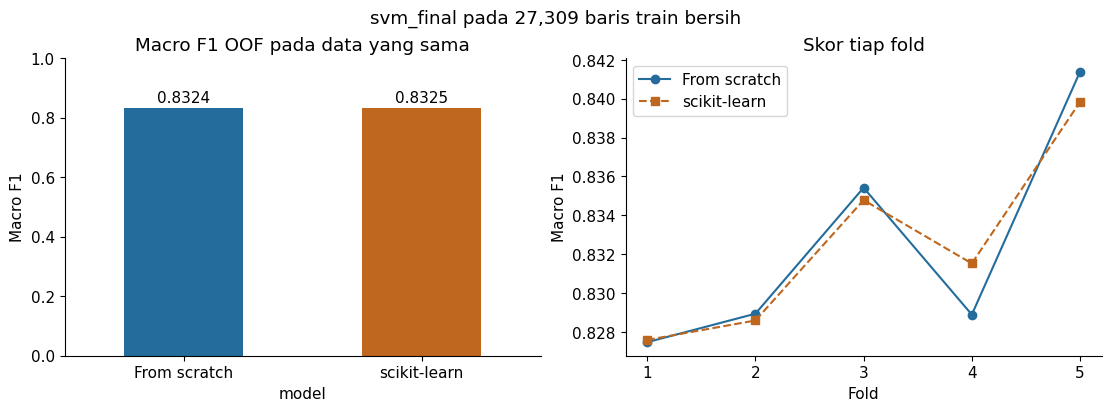

Macro F1 OOF from scratch sebesar **0.8324**, sedangkan scikit-learn sebesar **0.8325**. Selisihnya -0.0000. Std pada tabel menunjukkan penyebaran skor antar-fold, bukan confidence interval.

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
comparison['macro_f1'].plot.bar(ax=axes[0], color=['#246c9c', '#bf671f'], rot=0)
axes[0].set(title='Macro F1 OOF pada data yang sama', ylabel='Macro F1', ylim=(0, 1))
for i, value in enumerate(comparison['macro_f1']):
    axes[0].text(i, value + 0.02, f'{value:.4f}', ha='center')
axes[1].plot(range(1, N_FOLDS + 1), scratch_fold_scores, 'o-', label='From scratch', color='#246c9c')
axes[1].plot(range(1, N_FOLDS + 1), reference_fold_scores, 's--', label='scikit-learn', color='#bf671f')
axes[1].set(title='Skor tiap fold', xlabel='Fold', ylabel='Macro F1', xticks=range(1, N_FOLDS + 1))
axes[1].legend()
fig.suptitle(f'{EXP_NAME} pada {len(y):,} baris train bersih')
fig.savefig(FIG_DIR / 'comparison.png', dpi=130)
plt.show()
display(Markdown(f"Macro F1 OOF from scratch sebesar **{scratch_score:.4f}**, "
                 f"sedangkan scikit-learn sebesar **{reference_score:.4f}**. "
                 f"Selisihnya {scratch_score - reference_score:+.4f}. "
                 "Std pada tabel menunjukkan penyebaran skor antar-fold, bukan confidence interval."))

---

# Saving and Loading Models <a name="9"></a>

---

Preprocessor template dan SVM dilatih pada seluruh train yang dipakai dalam run ini.
Bundle menyimpan preprocessor, model, parameter terpilih, dan threshold OOF.
Hasil prediksi setelah load diperiksa terhadap hasil sebelum penyimpanan.

In [18]:
final_prep = FinalSVMPreprocessor()
final_X_train = final_prep.fit_transform(train_clean)
final_X_test = final_prep.transform(test_raw)
assert final_X_train.columns.equals(final_X_test.columns)
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as final_messages:
    warnings.simplefilter('always', RuntimeWarning)
    final_model = SVM(**COMMON_PARAMS, **PARAMS).fit(final_X_train, y)
    probability_before = final_model.predict_proba(final_X_test)
if not final_model.converged_ or final_messages:
    raise RuntimeError('Training final belum bersih: ' + ' | '.join(str(w.message) for w in final_messages))
save_model(dict(model=final_model, preprocessor_state=vars(final_prep), preprocessor_class='FinalSVMPreprocessor', threshold=threshold,
                train_rows=len(train_clean), smoke_test=SMOKE_TEST, parameters=PARAMS,
                train_sha256=hashlib.sha256((DATA_DIR / 'train.csv').read_bytes()).hexdigest()), MODEL_PATH)
loaded_bundle = load_model(MODEL_PATH)
with threadpool_limits(limits=1):
    loaded_probability = loaded_bundle['model'].predict_proba(loaded_bundle['preprocessor'].transform(test_raw))
np.testing.assert_array_equal(probability_before, loaded_probability)
print('Model run ini:', MODEL_PATH)

Model run ini: C:\Users\Akram\Documents\Semester5\AI\IF3170_G17_DerbyCounty\output\experiments\svm_final\template_rerun\svm_final.pkl


---

# Kaggle Submission <a name="10"></a>

---

Notebook ini hanya menghasilkan satu CSV final, `submission_svm_final.csv`,
dari satu model SVM terpilih dan threshold OOF. Model disimpan agar seluruh pipeline
dapat dipakai ulang. Tidak ada ekspor kandidat atau reproduksi CSV historis di notebook ini.
Sel ekspor tidak mengunggah CSV ke Kaggle secara otomatis.

Hasil submission Kaggle **58803590** telah selesai dinilai dengan public score **0,85189**. Skor ini berlaku untuk CSV final yang disubmit, bukan untuk perubahan konfigurasi selanjutnya.

In [19]:
rerun_pred = (loaded_probability >= loaded_bundle['threshold']).astype(int)
submission = pd.DataFrame({'id': test_raw['id'], TARGET: rerun_pred})
assert submission.shape == sample.shape and submission.columns.equals(sample.columns)
assert submission['id'].equals(sample['id']) and submission[TARGET].isin([0, 1]).all()
submission.to_csv(RERUN_SUB_PATH, index=False)
pd.testing.assert_frame_equal(submission, pd.read_csv(RERUN_SUB_PATH, dtype={'id': str}))
print('Satu CSV final:', RERUN_SUB_PATH)
display(submission.head())

Satu CSV final: C:\Users\Akram\Documents\Semester5\AI\IF3170_G17_DerbyCounty\output\experiments\svm_final\template_rerun\submission_svm_final.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

## Confusion Matrix

Analisis menggunakan prediksi OOF from scratch dengan threshold terpilih.
FP berarti pemesanan sebenarnya tidak batal tetapi diprediksi batal.
FN berarti pemesanan sebenarnya batal tetapi diprediksi tidak batal.

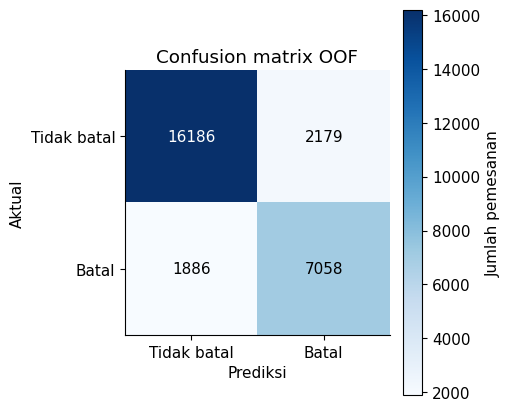

F1 tidak batal    0.8884
F1 batal          0.7764
dtype: float64

In [20]:
oof_pred = (oof_scratch >= threshold).astype(int)
matrix = confusion_matrix(y, oof_pred)
fig, ax = plt.subplots(figsize=(5, 4), layout='constrained')
image = ax.imshow(matrix, cmap='Blues')
for (row, col), value in np.ndenumerate(matrix):
    ax.text(col, row, str(value), ha='center', va='center',
            color='white' if value > matrix.max() / 2 else 'black')
ax.set(title='Confusion matrix OOF', xlabel='Prediksi', ylabel='Aktual',
       xticks=[0, 1], yticks=[0, 1], xticklabels=['Tidak batal', 'Batal'],
       yticklabels=['Tidak batal', 'Batal'])
fig.colorbar(image, ax=ax, label='Jumlah pemesanan')
fig.savefig(FIG_DIR / 'confusion_matrix.png', dpi=130)
plt.show()
display(pd.Series(f1_per_class(y, oof_pred), index=['F1 tidak batal', 'F1 batal']).round(4))

## Kesalahan per Kelompok

In [21]:
errors = train_clean[['booking_channel', 'special_requests']].copy()
errors['salah'] = (oof_pred != y).astype(int)
error_groups = errors.groupby('booking_channel', dropna=False)['salah'].agg(['count', 'mean'])
error_groups.columns = ['jumlah', 'proporsi_salah']
display(error_groups.sort_values('proporsi_salah', ascending=False).round(4))
display(errors.groupby('special_requests', dropna=False)['salah'].agg(['count', 'mean']).round(4))
tn, fp, fn, tp = matrix.ravel()
display(Markdown(f"Kesalahan OOF terdiri dari **{fp} FP** dan **{fn} FN**. "
                 "Proporsi salah per kelompok harus dibaca bersama jumlah sampelnya. "
                 "Kelompok berukuran kecil belum cukup untuk menyimpulkan pola umum."))

,jumlah,proporsi_salah
booking_channel,,
Airline,88,0.1818
Online Travel Agent,17507,0.1813
Offline Agent,7902,0.0957
Corporate,1512,0.0774
Complimentary,300,0.0067


,count,mean
special_requests,,
0.0,12678,0.1640
1.0,8323,0.1493
2.0,3246,0.0866
3.0,496,0.0000
4.0,60,0.0000
5.0,7,0.0000
NaN,2499,0.1849


Kesalahan OOF terdiri dari **2179 FP** dan **1886 FN**. Proporsi salah per kelompok harus dibaca bersama jumlah sampelnya. Kelompok berukuran kecil belum cukup untuk menyimpulkan pola umum.

---

# Bonus <a name="12"></a>

---

## Visualisasi dua fitur

Setiap kernel dilatih ulang menggunakan dua fitur untuk menggambarkan batas
keputusannya. Grafik ini tidak memproyeksikan model yang dilatih pada seluruh fitur.

Garis penuh menunjukkan $f(x)=0$, sedangkan garis putus-putus menunjukkan
$f(x)=\pm1$. Lingkaran menandai support vector. Pada kernel non-linear, jarak
antarkontur dalam gambar tidak menyatakan lebar margin Euclidean di ruang asal.
Support vector pada SVM soft-margin juga dapat berada di dalam margin.

Bonus memakai preprocessing template dan variabel terpisah dari eksperimen utama.
Visualisasi melatih tiga model pada dua fitur, sedangkan PSO mengoptimasi kernel terpilih pada data pengembangan dan holdout terpisah. Bonus tidak mengganti model final
dan tidak menghasilkan CSV submission tambahan.

Holdout bonus terpisah dalam pencarian PSO, tetapi bukan evaluasi independen atas pemilihan kernel utama.

In [22]:
def prepare_bonus():
    # Siapkan sampel bonus terpisah dari populasi evaluasi utama.
    # PSO hanya memakai data pengembangan. Holdout dievaluasi setelah pencarian selesai.
    train = train_clean.copy()
    sample_idx, _ = train_test_split(np.arange(len(train)), train_size=DEV_SIZE + HOLDOUT_SIZE,
                                     stratify=train[TARGET], random_state=SEED)
    dev_idx, holdout_idx = train_test_split(sample_idx, test_size=HOLDOUT_SIZE,
                                           stratify=train.iloc[sample_idx][TARGET], random_state=SEED)
    assert not np.intersect1d(dev_idx, holdout_idx).size
    dev = train.iloc[dev_idx].reset_index(drop=True)
    holdout = train.iloc[holdout_idx].reset_index(drop=True)
    y_dev = dev[TARGET].to_numpy()
    folds = stratified_kfold(y_dev, n_splits=5, seed=SEED)
    assert np.array_equal(np.sort(np.concatenate([va for _, va in folds])), np.arange(DEV_SIZE))
    # Fit preprocessing sekali per train fold dan pakai ulang transform yang sama untuk semua kandidat.
    prepared_folds = []
    for tr, va in folds:
        assert not np.intersect1d(tr, va).size
        prep = FinalSVMPreprocessor()
        prepared_folds.append((tr, va, prep.fit_transform(dev.iloc[tr]).to_numpy(),
                               prep.transform(dev.iloc[va]).to_numpy()))
    display(pd.DataFrame({'bagian': ['Pengembangan', 'Holdout'],
                          'baris': [len(dev), len(holdout)],
                          'proporsi_batal': [y_dev.mean(), holdout[TARGET].mean()]}).round(4))
    return dev, holdout, y_dev, folds, prepared_folds

In [23]:
def visualize_bonus(dev, y_dev):
    # Gunakan waktu tunggu dan tarif kamar untuk memperlihatkan bentuk batas keputusan.
    visual_idx, _ = train_test_split(np.arange(len(dev)), train_size=VISUAL_SIZE,
                                     stratify=y_dev, random_state=SEED)
    features_2d = ['days_before_arrival', 'nightly_rate_idr']
    raw_2d = dev.iloc[visual_idx][features_2d]
    # Hitung median dan statistik standardisasi dari sampel visualisasi. Tarif nol tetap disertakan.
    filled_2d = raw_2d.fillna(raw_2d.median())
    X_2d = ((filled_2d - filled_2d.mean()) / filled_2d.std(ddof=0).replace(0, 1)).to_numpy()
    y_2d = y_dev[visual_idx]
    assert X_2d.shape == (VISUAL_SIZE, 2) and np.isfinite(X_2d).all()
    # Latih tiga model 2D pada sampel yang sama agar bentuk batasnya dapat dibandingkan.
    visual_models = {}
    with threadpool_limits(limits=1):
        for kernel in ['linear', 'poly', 'gaussian']:
            model = SVM(kernel=kernel, C=1, degree=3, coef0=1, gamma='scale',
                        tol=0.01, max_iter=1000, seed=SEED, device=DEVICE).fit(X_2d, y_2d)
            assert model.converged_
            visual_models[kernel] = model
        fig = boundary_plot(X_2d, y_2d, visual_models,
                            {'linear': 'Linear', 'poly': 'Polynomial', 'gaussian': 'Gaussian'})
    visual_results = [dict(kernel=k, support_vectors=len(m.support_), converged=bool(m.converged_))
                      for k, m in visual_models.items()]
    show_plot(fig, FIG_DIR / (EXP_NAME + '_boundaries.png'))
    return visual_results

,bagian,baris,proporsi_batal
0,Pengembangan,800,0.3275
1,Holdout,400,0.3275


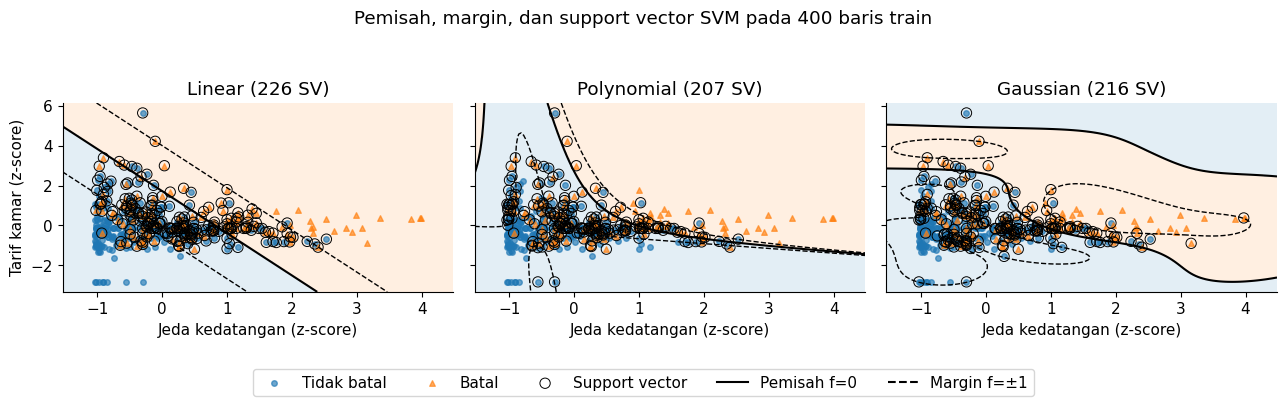

In [24]:
bonus_dev, bonus_holdout, bonus_y, bonus_folds, bonus_prepared = prepare_bonus()
bonus_visual = visualize_bonus(bonus_dev, bonus_y)

## Optimasi PSO

Setiap partikel mewakili kandidat hyperparameter $x=(\log_{10}C,\log_{10}g)$ dengan
$\gamma=g\,\gamma_{baseline}$. Posisi kandidat diperbarui berdasarkan posisi terbaik
partikel $p_i$ dan posisi terbaik seluruh swarm $g^*$:

$$v_i\leftarrow wv_i+c_1r_1(p_i-x_i)+c_2r_2(g^*-x_i),\qquad x_i\leftarrow x_i+v_i.$$

Fitness kandidat dihitung dari Macro F1 OOF setelah pemilihan threshold. PSO
mencari hyperparameter, sementara SLSQP melatih SVM pada setiap kandidat. Nilai
fitness terbaik dipertahankan selama pencarian, tetapi peningkatan pada holdout
dan pencapaian optimum global tetap tidak terjamin.

Implementasi PSO mengacu pada referensi [1] dan [2]. Penerapannya untuk tuning SVM
mengacu pada referensi [3]. Eksperimen ini tidak menerapkan feature selection yang
dibahas dalam penelitian tersebut.

Kernel mengikuti model SVM terpilih. Linear hanya mencari C. Kernel non-linear mencari C dan faktor gamma, dengan degree dan coef0 tetap mengikuti hasil screening.

Gamma baseline mengikuti nilai numerik terpilih atau gamma scale dari train fold jika konfigurasi memakai scale.

In [25]:
# PSO dengan inertia weight: Kennedy & Eberhart (1995), doi:10.1109/ICNN.1995.488968.
# Shi & Eberhart (1998), doi:10.1109/ICEC.1998.699146.
def particle_swarm(objective, bounds, initial, particles=8, generations=4, seed=42):
    bounds = np.asarray(bounds, dtype=float)
    initial = np.asarray(initial, dtype=float)
    if (bounds.shape != (len(initial), 2) or not np.isfinite(bounds).all()
            or not np.isfinite(initial).all() or np.any(bounds[:, 0] >= bounds[:, 1])
            or np.any(initial < bounds[:, 0]) or np.any(initial > bounds[:, 1])
            or particles < 2 or generations < 1):
        raise ValueError('Batas, posisi awal, dan anggaran PSO tidak valid.')
    rng = np.random.default_rng(seed)
    lower, upper = bounds.T
    positions = rng.uniform(lower, upper, size=(particles, len(initial)))
    # Sertakan baseline sebagai satu posisi awal, lalu simpan pengalaman terbaik tiap partikel.
    positions[0] = initial
    velocity = np.zeros_like(positions)
    personal = positions.copy()
    personal_scores = np.full(particles, -np.inf)
    trace = []
    for generation in range(generations):
        scores = np.array([objective(position.copy()) for position in positions])
        if not np.isfinite(scores).all():
            raise ValueError('Fitness PSO harus finite.')
        # Perbarui personal best dan global best berdasarkan fitness yang benar-benar dievaluasi.
        improved = scores > personal_scores
        personal[improved], personal_scores[improved] = positions[improved], scores[improved]
        best = int(np.argmax(personal_scores))
        global_best = personal[best].copy()
        trace.append(float(personal_scores[best]))
        if generation + 1 < generations:
            # Inertia 0.7 mempertahankan sebagian arah. Bobot 1.5 menyeimbangkan pengalaman pribadi dan swarm.
            velocity = (0.7 * velocity
                        + 1.5 * rng.random(positions.shape) * (personal - positions)
                        + 1.5 * rng.random(positions.shape) * (global_best - positions))
            # Batasi langkah dan posisi agar pencarian tetap berada dalam rentang hyperparameter.
            velocity = np.clip(velocity, -0.25 * (upper - lower), 0.25 * (upper - lower))
            positions = np.clip(positions + velocity, lower, upper)
    return global_best, np.asarray(trace)

# Uji independen pada fungsi cekung dengan optimum diketahui di (0.3, -0.4).
def check_swarm():
    visited = []
    target = np.array([0.3, -0.4])
    def objective(point):
        assert ((point >= -1) & (point <= 1)).all()
        visited.append(point)
        return -float(np.sum((point - target) ** 2))
    args = dict(bounds=[[-1, 1], [-1, 1]], initial=[0, 0], particles=8, generations=30)
    best, history = particle_swarm(objective, **args)
    assert len(visited) == 240 and np.all(np.diff(history) >= 0)
    np.testing.assert_allclose(best, target, atol=0.02)
    repeated, _ = particle_swarm(objective, **args)
    np.testing.assert_array_equal(best, repeated)
check_swarm()
print('PSO: batas posisi, anggaran, perbaikan fitness, optimum uji, dan seed lolos.')

PSO: batas posisi, anggaran, perbaikan fitness, optimum uji, dan seed lolos.


In [26]:
def search_bonus(y_dev, folds, prepared_folds):
    BASE_PARAMS = dict(COMMON_PARAMS, **{k: v for k, v in PARAMS.items() if k not in ('C', 'gamma')})
    nonlinear = PARAMS['kernel'] != 'linear'
    # Nilai tiap kandidat PSO dengan fold dan preprocessing yang sama.
    # Solver yang gagal atau belum konvergen menghentikan evaluasi kandidat.
    evaluations = []
    def evaluate(position):
        # Skala log menjadikan perpindahan partikel sebagai perubahan rasio C dan gamma.
        C = 10.0 ** position[0]
        gamma_factor = 10.0 ** position[1] if nonlinear else 1.0
        oof = np.full(DEV_SIZE, np.nan)
        started = time.perf_counter()
        for tr, va, X_tr, X_va in prepared_folds:
            # Faktor 1 memakai gamma baseline kernel terpilih. Holdout tidak menentukan gamma.
            base_gamma = PARAMS.get('gamma', 'scale')
            if isinstance(base_gamma, str):
                base_gamma = 1.0 / (X_tr.shape[1] * X_tr.var())
            gamma = gamma_factor * base_gamma
            with warnings.catch_warnings(record=True) as messages:
                warnings.simplefilter('always', RuntimeWarning)
                model = SVM(**BASE_PARAMS, C=C, gamma=gamma).fit(X_tr, y_dev[tr])
            assert model.converged_ and not messages, [str(m.message) for m in messages]
            oof[va] = model.predict_proba(X_va)
        assert np.isfinite(oof).all() and ((oof >= 0) & (oof <= 1)).all()
        threshold, score = best_threshold(y_dev, oof)
        assert np.isclose(score, f1_score(y_dev, oof >= threshold, average='macro'))
        evaluations.append(dict(evaluation=len(evaluations) + 1, C=float(C),
                                gamma_factor=float(gamma_factor), threshold=threshold,
                                oof_macro_f1=score,
                                fold_std=float(fold_scores(y_dev, oof, folds, threshold).std()),
                                seconds=time.perf_counter() - started))
        print(f'Kandidat {len(evaluations):02d}/{PARTICLES * GENERATIONS}: '
              f'C={C:.3g}, faktor gamma={gamma_factor:.3g}, OOF={score:.4f}', flush=True)
        return score

    # Rentang C 0.01–10 dan faktor gamma 0.05–5 mencakup penalti serta lebar kernel di sekitar baseline.
    started = time.perf_counter()
    with threadpool_limits(limits=1):
        best_position, history = particle_swarm(
            evaluate, bounds=[[-2, 1]] + ([[np.log10(0.05), np.log10(5)]] if nonlinear else []),
            initial=[np.log10(PARAMS['C'])] + ([0.0] if nonlinear else []),
            particles=PARTICLES, generations=GENERATIONS, seed=SEED)
    search_seconds = time.perf_counter() - started
    evaluations = pd.DataFrame(evaluations)
    # Ambil baseline awal dan kandidat pemenang sesuai posisi terbaik PSO.
    baseline = evaluations.iloc[0].to_dict()
    matches = np.isclose(evaluations['C'], 10.0 ** best_position[0]) & np.isclose(
        evaluations['gamma_factor'], 10.0 ** best_position[1] if nonlinear else 1.0)
    best = evaluations.loc[matches].iloc[0].to_dict()
    np.testing.assert_allclose(10.0 ** best_position,
                               [best['C']] + ([best['gamma_factor']] if nonlinear else []))
    assert len(evaluations) == PARTICLES * GENERATIONS
    assert history[-1] >= baseline['oof_macro_f1'] and np.all(np.diff(history) >= 0)
    display(evaluations.nlargest(5, 'oof_macro_f1').round(4))
    print(f'Pencarian selesai: {search_seconds:.1f} detik.')
    return evaluations, baseline, best, history, search_seconds

In [27]:
bonus_evaluations, bonus_baseline, bonus_best, bonus_history, bonus_seconds = search_bonus(
    bonus_y, bonus_folds, bonus_prepared)

Kandidat 01/32: C=0.3, faktor gamma=1, OOF=0.7705


Kandidat 02/32: C=0.352, faktor gamma=0.186, OOF=0.7707


Kandidat 03/32: C=0.0145, faktor gamma=0.292, OOF=0.7609


Kandidat 04/32: C=0.168, faktor gamma=0.0616, OOF=0.7468


Kandidat 05/32: C=0.014, faktor gamma=4.98, OOF=0.6045


Kandidat 06/32: C=0.906, faktor gamma=0.147, OOF=0.7726


... (24 outputs left out)

Kandidat 31/32: C=0.321, faktor gamma=0.208, OOF=0.7693


Kandidat 32/32: C=1.36, faktor gamma=0.202, OOF=0.7700


,evaluation,C,gamma_factor,threshold,oof_macro_f1,fold_std,seconds
20,21,0.4429,0.4981,0.35,0.7796,0.0353,1.4658
19,20,0.4665,0.3199,0.39,0.7791,0.0237,2.0277
22,23,1.0218,0.4440,0.41,0.7777,0.0359,2.2459
9,10,0.4692,0.1662,0.41,0.7745,0.0150,8.4279
8,9,0.6911,0.3162,0.41,0.7735,0.0253,7.5013


Pencarian selesai: 133.7 detik.


### Evaluasi Holdout PSO

In [28]:
def compare_bonus(dev, holdout, y_dev, baseline, best):
    BASE_PARAMS = dict(COMMON_PARAMS, **{k: v for k, v in PARAMS.items() if k not in ('C', 'gamma')})
    # Latih ulang baseline dan pemenang pada data pengembangan, lalu nilai holdout.
    # Threshold tetap berasal dari OOF. Hasil holdout tidak digunakan untuk memilih kandidat baru.
    prep_final = FinalSVMPreprocessor()
    X_dev = prep_final.fit_transform(dev).to_numpy()
    X_holdout = prep_final.transform(holdout).to_numpy()
    y_holdout = holdout[TARGET].to_numpy()
    comparison_rows = []
    with threadpool_limits(limits=1):
        for name, candidate in [('Baseline SVM', baseline), ('SVM + PSO', best)]:
            base_gamma = PARAMS.get('gamma', 'scale')
            if isinstance(base_gamma, str):
                base_gamma = 1.0 / (X_dev.shape[1] * X_dev.var())
            gamma = candidate['gamma_factor'] * base_gamma
            started = time.perf_counter()
            with warnings.catch_warnings(record=True) as messages:
                warnings.simplefilter('always', RuntimeWarning)
                model = SVM(**BASE_PARAMS, C=candidate['C'], gamma=gamma).fit(X_dev, y_dev)
            assert model.converged_ and not messages, [str(m.message) for m in messages]
            pred = model.predict(X_holdout, threshold=candidate['threshold'])
            score = macro_f1(y_holdout, pred)
            assert np.isclose(score, f1_score(y_holdout, pred, average='macro'))
            comparison_rows.append(dict(model=name, C=candidate['C'], gamma_factor=candidate['gamma_factor'],
                                        threshold=candidate['threshold'], oof_macro_f1=candidate['oof_macro_f1'],
                                        fold_std=candidate['fold_std'], holdout_macro_f1=score,
                                        fit_seconds=time.perf_counter() - started))
    comparison = pd.DataFrame(comparison_rows).set_index('model')
    display(comparison.round(4))
    return comparison

In [29]:
bonus_comparison = compare_bonus(bonus_dev, bonus_holdout, bonus_y, bonus_baseline, bonus_best)

,C,gamma_factor,threshold,oof_macro_f1,fold_std,holdout_macro_f1,fit_seconds
model,,,,,,,
Baseline SVM,0.3000,1.0000,0.36,0.7705,0.0398,0.8039,0.4548
SVM + PSO,0.4429,0.4981,0.35,0.7796,0.0353,0.7940,1.0482


### Hasil dan Analisis PSO

In [30]:
def report_bonus(comparison, evaluations, baseline, best, history, search_seconds, dev, holdout, visual_results):
    # Plot riwayat fitness serta perbandingan skor seleksi dengan holdout.
    fig = pso_plot(history, comparison, DEV_SIZE, HOLDOUT_SIZE)
    show_plot(fig, FIG_DIR / (EXP_NAME + '_pso.png'))

    # Jelaskan hasil yang teramati, termasuk jika peningkatan OOF tidak bertahan di holdout.
    oof_gain = comparison.iloc[1]['oof_macro_f1'] - comparison.iloc[0]['oof_macro_f1']
    holdout_gain = comparison.iloc[1]['holdout_macro_f1'] - comparison.iloc[0]['holdout_macro_f1']
    holdout_result = 'meningkat' if holdout_gain > 0 else ('tetap' if holdout_gain == 0 else 'menurun')
    display(Markdown(
        f"PSO memilih C={best['C']:.4g}, faktor gamma={best['gamma_factor']:.4g}, "
        f"dan threshold={best['threshold']:.2f}. Macro F1 OOF berubah dari "
        f"{baseline['oof_macro_f1']:.4f} menjadi {best['oof_macro_f1']:.4f}, "
        f"dengan selisih {oof_gain:+.4f}. Skor ini digunakan untuk memilih kandidat. "
        f"\n\nPada holdout terpisah, Macro F1 {holdout_result} dari "
        f"**{comparison.iloc[0]['holdout_macro_f1']:.4f}** menjadi "
        f"**{comparison.iloc[1]['holdout_macro_f1']:.4f}** (selisih {holdout_gain:+.4f}). "
        f"Pencarian memakai {len(evaluations)} evaluasi dengan waktu {search_seconds:.1f} detik. "
        "\n\nEksperimen dengan satu seed dan holdout berukuran kecil belum cukup untuk "
        "menyimpulkan bahwa konfigurasi terpilih lebih baik secara umum atau meningkatkan "
        "skor Kaggle. Jumlah evaluasi yang terbatas juga belum membuktikan optimum global."
    ))
    # Simpan kandidat, metrik, hash data, dan ID pembagian agar eksperimen dapat ditelusuri.
    evaluations.to_csv(RUN_DIR / 'evaluations.csv', index=False)
    comparison.to_csv(RUN_DIR / 'bonus_comparison.csv')
    summary = dict(seed=SEED, dev_rows=DEV_SIZE, holdout_rows=HOLDOUT_SIZE,
                   particles=PARTICLES, generations=GENERATIONS, search_seconds=search_seconds,
                   train_sha256=hashlib.sha256((DATA_DIR / 'train.csv').read_bytes()).hexdigest(),
                   dev_ids=dev['id'].tolist(), holdout_ids=holdout['id'].tolist(),
                   visualizations=visual_results, history=history.tolist(),
                   comparison=comparison.reset_index().to_dict(orient='records'))
    (RUN_DIR / 'bonus_results.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    print('Gambar:', (FIG_DIR / (EXP_NAME + '_boundaries.png')).relative_to(ROOT),
          'dan', (FIG_DIR / (EXP_NAME + '_pso.png')).relative_to(ROOT))

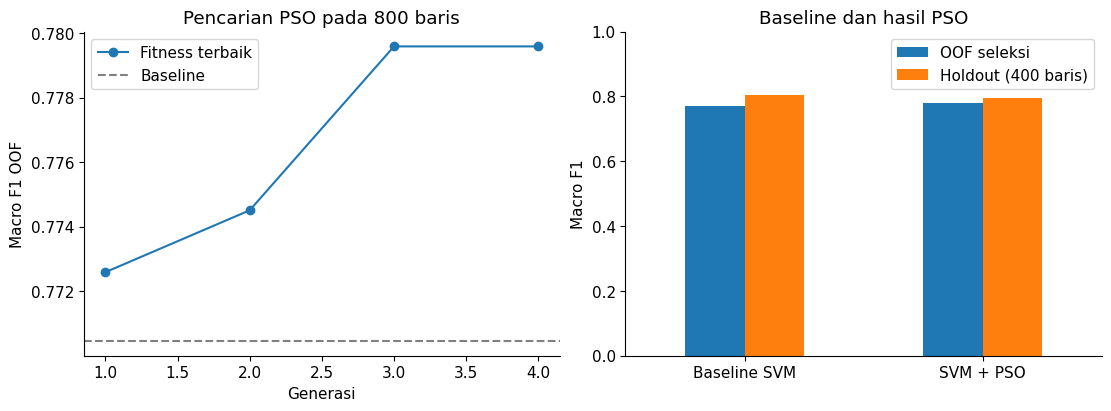

PSO memilih C=0.4429, faktor gamma=0.4981, dan threshold=0.35. Macro F1 OOF berubah dari 0.7705 menjadi 0.7796, dengan selisih +0.0091. Skor ini digunakan untuk memilih kandidat. 

Pada holdout terpisah, Macro F1 menurun dari **0.8039** menjadi **0.7940** (selisih -0.0098). Pencarian memakai 32 evaluasi dengan waktu 133.7 detik. 

Eksperimen dengan satu seed dan holdout berukuran kecil belum cukup untuk menyimpulkan bahwa konfigurasi terpilih lebih baik secara umum atau meningkatkan skor Kaggle. Jumlah evaluasi yang terbatas juga belum membuktikan optimum global.

Gambar: output\experiments\svm_final\template_rerun\figures\svm_final_boundaries.png dan output\experiments\svm_final\template_rerun\figures\svm_final_pso.png


In [31]:
report_bonus(bonus_comparison, bonus_evaluations, bonus_baseline, bonus_best, bonus_history,
             bonus_seconds, bonus_dev, bonus_holdout, bonus_visual)

#### Insights

PSO memilih C dan faktor gamma berdasarkan Macro F1 OOF pada data pengembangan.
Threshold berasal dari OOF tersebut dan tetap digunakan saat evaluasi holdout.
Kenaikan fitness pencarian belum menjamin kenaikan skor holdout atau skor Kaggle.
Hasil aktual dan perbandingannya ditampilkan oleh sel bonus, termasuk jika holdout menurun.

---

# Referensi <a name="13"></a>

---

- Preprocessing final didefinisikan langsung di notebook. Cleaning bersama:
- Preprocessing mengikuti fungsi `prepare` pada template `main.ipynb` kelompok.
- Optimasi blok QP memakai [SciPy SLSQP](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html).
SLSQP merupakan solver numerik untuk objective kuadratik dengan kendala equality dan bounds.
- Kalibrasi sigmoid memakai [SciPy BFGS](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-bfgs.html).
BFGS memperbarui parameter sigmoid melalui pendekatan matriks kelengkungan.
- J. Kennedy dan R. Eberhart, *Particle Swarm Optimization*, ICNN, 1995.
[DOI 10.1109/ICNN.1995.488968](https://doi.org/10.1109/ICNN.1995.488968).
- Y. Shi dan R. Eberhart, *A Modified Particle Swarm Optimizer*, IEEE ICEC, 1998.
[DOI 10.1109/ICEC.1998.699146](https://doi.org/10.1109/ICEC.1998.699146).
- S.-W. Lin, K.-C. Ying, S.-C. Chen, dan Z.-J. Lee,
*Particle swarm optimization for parameter determination and feature selection of support vector machines*,
Expert Systems with Applications, 2008.
[DOI 10.1016/j.eswa.2007.08.088](https://doi.org/10.1016/j.eswa.2007.08.088).
Notebook ini mengadaptasi pencarian parameter SVM dan tidak menerapkan feature selection pada penelitian tersebut.

In [32]:
run_summary = dict(experiment=EXP_NAME, smoke_test=SMOKE_TEST, seed=SEED,
                   train_rows=len(train_clean), test_rows=len(test_raw), parameters=PARAMS,
                   solver='SLSQP', calibration='BFGS',
                   comparison=comparison.reset_index().to_dict(orient='records'),
                   kaggle_public_score=KAGGLE_PUBLIC_SCORE, kaggle_submission_id=KAGGLE_SUBMISSION_ID,
                   model_path=str(MODEL_PATH.relative_to(ROOT)),
                   csv_path=str(RERUN_SUB_PATH.relative_to(ROOT)))
(RUN_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2), encoding='utf-8')
print('Ringkasan hasil:', RUN_DIR / 'run_summary.json')

Ringkasan hasil: C:\Users\Akram\Documents\Semester5\AI\IF3170_G17_DerbyCounty\output\experiments\svm_final\template_rerun\run_summary.json
